# Build sum-of-products KEO for formic acid (HCOOH) using Z-matrix coordinates

First, we compare the sum-of-products form with the numerical approach using small 1D grids to avoid generating large multidimensional representations that are needed only for comparison.

Then, we evaluate and plot the sum-of-product form along the torsional coordinate.

In [1]:
import jax
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import constants

from keosop.gmat import Gmat
from keosop.numerical.keo import batch_Gmat, com
from keosop.numerical.zmat import internal_to_cartesian_jax
from keosop.zmat import cartesian_to_internal, internal_to_cartesian

sns.set_theme(style="ticks", context="paper", font_scale=1.5)
plt.rcParams["figure.dpi"] = 300
plt.rcParams.update({"text.usetex": True, "font.family": "serif", "font.size": 14})

jax.config.update("jax_enable_x64", True)

# converts G-matrix to cm^-1 units
G_to_invcm = (
    constants.value("Planck constant")
    * constants.value("Avogadro constant")
    * 1e16
    / (4.0 * np.pi**2 * constants.value("speed of light in vacuum"))
    * 1e5
)

Define Z-matrix connections

In [2]:
masses = np.array([12.000000, 15.994910, 15.994910, 1.007825, 1.007825])

zmat_connections = [
    (0, 0, 0, 0), # C
    (1, 0, 0, 0), # O1 - C
    (1, 2, 0, 0), # O2 - C - O1
    (1, 2, 3, 0), # H1 - C - O1 - O2
    (3, 1, 2, 0), # H2 - O2 - C - O1
]

Define one-dimensional grids for the internal coordinate representation and construct the $G$-matrix in sum-of-products form

In [3]:
rad = np.pi / 180.0

grids = [
    np.linspace(0.8, 2.6, 5),
    np.linspace(0.8, 2.6, 5),
    np.linspace(0.8, 2.6, 5),
    np.linspace(0.8, 2.6, 5),
    np.linspace(60 * rad, 160 * rad, 5),
    np.linspace(60 * rad, 160 * rad, 5),
    np.linspace(60 * rad, 160 * rad, 5),
    np.linspace(100 * rad, 260 * rad, 5),
    np.linspace(0 * rad, 360 * rad, 5),
]

ncoo = len(grids)

gmat = Gmat(
    grids,
    masses,
    lambda q: internal_to_cartesian(zmat_connections, q),
    lambda xyz: cartesian_to_internal(zmat_connections, xyz),
    compress_tol=1e-6,
    compress_zero_tol=1e-8,
    compress_identity_tol=1e-8,
)

gvib_sop, grovib_sop, grot_sop = gmat.run(return_rot=True)

print("Number of terms in Gvib_{i,j}\n i  j no.terms")
for i in range(ncoo):
    for j in range(i, ncoo):
        print(f"{i:2d} {j:2d} {gvib_sop[i, j].nterms:6d}")

print("\nNumber of terms in Grovib_{i,j}\n i  j no.terms")
for i in range(3):
    for j in range(ncoo):
        print(f"{i:2d} {j:2d} {grovib_sop[i, j].nterms:6d}")

print("\nNumber of terms in Grot_{i,j}\n i  j no.terms")
for i in range(3):
    for j in range(i, 3):
        print(f"{i:2d} {j:2d} {grot_sop[i, j].nterms:6d}")

Number of terms in Gvib_{i,j}
 i  j no.terms
 0  0      1
 0  1      1
 0  2      1
 0  3      1
 0  4      2
 0  5      2
 0  6      1
 0  7      1
 0  8      1
 1  1      1
 1  2      2
 1  3      1
 1  4      1
 1  5      4
 1  6      2
 1  7      2
 1  8      1
 2  2      1
 2  3      1
 2  4      4
 2  5      1
 2  6      3
 2  7      2
 2  8      5
 3  3      1
 3  4      2
 3  5      1
 3  6      1
 3  7      1
 3  8      1
 4  4      4
 4  5      8
 4  6      5
 4  7      4
 4  8      4
 5  5      4
 5  6      6
 5  7      4
 5  8     10
 6  6      4
 6  7      7
 6  8      3
 7  7     10
 7  8     14
 8  8     10

Number of terms in Grovib_{i,j}
 i  j no.terms
 0  0      1
 0  1      1
 0  2      1
 0  3      1
 0  4      1
 0  5      2
 0  6      1
 0  7      4
 0  8      3
 1  0      1
 1  1      1
 1  2      1
 1  3      1
 1  4      2
 1  5      2
 1  6      1
 1  7      2
 1  8      1
 2  0      1
 2  1      1
 2  2      2
 2  3      1
 2  4      1
 2  5      4
 2  6     

Evaluate the $G$-matrix numerically on the multidimensional grid formed by the Cartesian product of the one-dimensional grids used to construct the sum-of-products representation

In [4]:
# build direct-product grid
product_grid = np.stack(np.meshgrid(*grids, indexing="ij"), axis=-1)
product_grid = product_grid.reshape(-1, len(grids))
print("Number of points:", len(product_grid))

# map each multidimensional grid point to its 1D grid indices
grid_indices = np.indices([len(grid) for grid in grids]).reshape(len(grids), -1).T

# compute G-matrix on grid
gmat = batch_Gmat(
    product_grid,
    masses,
    # lambda q: com(masses)(internal_to_cartesian_jax)(zmat_connections, q),
    lambda q: internal_to_cartesian_jax(zmat_connections, q),
)

gvib_num = gmat[:, :ncoo, :ncoo]
grovib_num = gmat[:, ncoo : ncoo + 3, :ncoo]
grot_num = gmat[:, ncoo : ncoo + 3, ncoo : ncoo + 3]

Number of points: 1953125


Calculate point-wise differences between the sum-of-products and numerical $G$-matrix

In [5]:
# evaluate one SOP term
def eval_sop_term(sop, iterm, inds):
    value = 1.0
    for k in range(sop.ncoo):
        value *= sop.terms[iterm][k][inds[k]]
    return value

# evaluate a complete SumProd object at one direct-product grid point
def eval_sop(sop, inds):
    return sum(
        eval_sop_term(sop, iterm, inds)
        for iterm in range(sop.nterms)
    )

In [6]:
# number of multidimensional grid points
npoints = product_grid.shape[0]

gvib_sop_eval = np.zeros((npoints, ncoo, ncoo), dtype=np.float64)
grot_sop_eval = np.zeros((npoints, 3, 3), dtype=np.float64)
grovib_sop_eval = np.zeros((npoints, 3, ncoo), dtype=np.float64)

# Gvib
for ipoint, inds in enumerate(grid_indices):
    for i in range(ncoo):
        for j in range(ncoo):
            gvib_sop_eval[ipoint, i, j] = eval_sop(gvib_sop[i, j], inds) * G_to_invcm


# Grot
for ipoint, inds in enumerate(grid_indices):
    for i in range(3):
        for j in range(3):
            grot_sop_eval[ipoint, i, j] = eval_sop(grot_sop[i, j], inds) * G_to_invcm


# Grovib
for ipoint, inds in enumerate(grid_indices):
    for i in range(3):
        for j in range(ncoo):
            grovib_sop_eval[ipoint, i, j] = (
                eval_sop(grovib_sop[i, j], inds) * G_to_invcm
            )

In [7]:
# differences

diff_vib = gvib_sop_eval - gvib_num
diff_rovib = grovib_sop_eval - grovib_num
diff_rot = grot_sop_eval - grot_num

abs_diff_vib = np.abs(diff_vib)
abs_diff_rovib = np.abs(diff_rovib)
abs_diff_rot = np.abs(diff_rot)

print("--- Gvib ---")
print("Maximum absolute difference:", np.max(abs_diff_vib))
print("Mean absolute difference:", np.mean(abs_diff_vib))
print("RMS difference:", np.sqrt(np.mean(diff_vib**2)))

print("\n--- Grovib ---")
print("Maximum absolute difference:", np.max(abs_diff_rovib))
print("Mean absolute difference:", np.mean(abs_diff_rovib))
print("RMS difference:", np.sqrt(np.mean(diff_rovib**2)))

print("\n--- Grot ---")
print("Maximum absolute difference:", np.max(abs_diff_rot))
print("Mean absolute difference:", np.mean(abs_diff_rot))
print("RMS difference:", np.sqrt(np.mean(diff_rot**2)))

--- Gvib ---
Maximum absolute difference: 1.375610736431554e-11
Mean absolute difference: 7.556595421410394e-15
RMS difference: 5.43910643308667e-14

--- Grovib ---
Maximum absolute difference: 7.73070496506989e-12
Mean absolute difference: 6.633520929388979e-15
RMS difference: 5.1979314543820135e-14

--- Grot ---
Maximum absolute difference: 6.252776074688882e-12
Mean absolute difference: 8.7063827446473e-15
RMS difference: 5.724958871092026e-14


In [8]:
print("--- Gvib element-wise errors ---")

for i in range(ncoo):
    for j in range(i, ncoo):
        d = diff_vib[:, i, j]
        max_abs = np.max(np.abs(d))
        rms = np.sqrt(np.mean(d**2))
        print(f"Gvib[{i},{j}]  " f"max abs = {max_abs:.3e}   " f"RMS = {rms:.3e}")

print("\n--- Grovib element-wise errors ---")

for i in range(3):
    for j in range(ncoo):
        d = diff_rovib[:, i, j]
        max_abs = np.max(np.abs(d))
        rms = np.sqrt(np.mean(d**2))
        print(f"Grovib[{i},{j}]  " f"max abs = {max_abs:.3e}   " f"RMS = {rms:.3e}")

print("\n--- Grot element-wise errors ---")

for i in range(3):
    for j in range(i, 3):
        d = diff_rot[:, i, j]
        max_abs = np.max(np.abs(d))
        rms = np.sqrt(np.mean(d**2))
        print(f"Grot[{i},{j}]  " f"max abs = {max_abs:.3e}   " f"RMS = {rms:.3e}")

--- Gvib element-wise errors ---
Gvib[0,0]  max abs = 7.105e-15   RMS = 3.527e-15
Gvib[0,1]  max abs = 7.050e-15   RMS = 1.819e-15
Gvib[0,2]  max abs = 6.883e-15   RMS = 1.495e-15
Gvib[0,3]  max abs = 2.049e-15   RMS = 3.924e-16
Gvib[0,4]  max abs = 2.043e-14   RMS = 2.121e-15
Gvib[0,5]  max abs = 1.532e-14   RMS = 1.863e-15
Gvib[0,6]  max abs = 1.332e-14   RMS = 1.612e-15
Gvib[0,7]  max abs = 5.432e-14   RMS = 1.434e-15
Gvib[0,8]  max abs = 4.152e-14   RMS = 1.503e-15
Gvib[1,1]  max abs = 3.109e-14   RMS = 4.882e-15
Gvib[1,2]  max abs = 3.020e-14   RMS = 2.186e-15
Gvib[1,3]  max abs = 3.775e-15   RMS = 6.855e-16
Gvib[1,4]  max abs = 5.862e-14   RMS = 3.951e-15
Gvib[1,5]  max abs = 8.971e-14   RMS = 3.367e-15
Gvib[1,6]  max abs = 9.381e-15   RMS = 1.034e-15
Gvib[1,7]  max abs = 2.274e-13   RMS = 6.825e-15
Gvib[1,8]  max abs = 4.435e-14   RMS = 1.720e-15
Gvib[2,2]  max abs = 4.974e-14   RMS = 4.803e-15
Gvib[2,3]  max abs = 1.630e-14   RMS = 5.882e-16
Gvib[2,4]  max abs = 7.550e-14   RMS

In [9]:
print("--- Gvib largest discrepancy ---")
idx = np.unravel_index(np.argmax(abs_diff_vib), abs_diff_vib.shape)
ipoint, i, j = idx

print("grid point :", ipoint)
print("coordinates:", np.asarray(product_grid[ipoint]))
print("element    :", (i, j))
print("SOP        :", gvib_sop_eval[ipoint, i, j])
print("reference  :", gvib_num[ipoint, i, j])
print("difference :", diff_vib[ipoint, i, j])

print("\n--- Grovib largest discrepancy ---")
idx = np.unravel_index(np.argmax(abs_diff_rovib), abs_diff_rovib.shape)
ipoint, i, j = idx

print("grid point :", ipoint)
print("coordinates:", np.asarray(product_grid[ipoint]))
print("element    :", (i, j))
print("SOP        :", grovib_sop_eval[ipoint, i, j])
print("reference  :", grovib_num[ipoint, i, j])
print("difference :", diff_rovib[ipoint, i, j])

print("\n--- Grot largest discrepancy ---")
idx = np.unravel_index(np.argmax(abs_diff_rot), abs_diff_rot.shape)
ipoint, i, j = idx

print("grid point :", ipoint)
print("coordinates:", np.asarray(product_grid[ipoint]))
print("element    :", (i, j))
print("SOP        :", grot_sop_eval[ipoint, i, j])
print("reference  :", grot_num[ipoint, i, j])
print("difference :", diff_rot[ipoint, i, j])

--- Gvib largest discrepancy ---
grid point : 343730
coordinates: [0.8        2.6        1.25       2.6        2.7925268  2.7925268
 2.7925268  2.44346095 0.        ]
element    : (np.int64(7), np.int64(7))
SOP        : 538.8482236165426
reference  : 538.8482236165563
difference : -1.375610736431554e-11

--- Grovib largest discrepancy ---
grid point : 15559
coordinates: [0.8        0.8        0.8        2.6        2.7925268  2.7925268
 1.91986218 2.44346095 6.28318531]
element    : (np.int64(2), np.int64(7))
SOP        : -321.42393777697373
reference  : -321.42393777698146
difference : 7.73070496506989e-12

--- Grot largest discrepancy ---
grid point : 15033
coordinates: [0.8        0.8        0.8        2.6        2.7925268  1.04719755
 1.48352986 2.44346095 4.71238898]
element    : (np.int64(2), np.int64(2))
SOP        : 194.21493568291763
reference  : 194.21493568292388
difference : -6.252776074688882e-12


Now, evaluate and plot the $G$-matrix elements in sum-of-products form on a 1D grid along the torsional coordinate

In [10]:
rad = np.pi / 180.0

grids = [
    np.linspace(1.2, 1.2, 1),
    np.linspace(1.2, 1.2, 1),
    np.linspace(1.1, 1.1, 1),
    np.linspace(0.97, 0.97, 1),
    np.linspace(120*rad, 120*rad, 1),
    np.linspace(120*rad, 120*rad, 1),
    np.linspace(120*rad, 120*rad, 1),
    np.linspace(180*rad, 180*rad, 1),
    np.linspace(0*rad, 360*rad, 100),
]

ncoo = len(grids)

gmat = Gmat(
    grids,
    masses,
    lambda q: internal_to_cartesian(zmat_connections, q),
    lambda xyz: cartesian_to_internal(zmat_connections, xyz),
)

gvib_sop, grovib_sop, grot_sop = gmat.run(return_rot=True)

In [11]:
product_grid = np.stack(np.meshgrid(*grids, indexing="ij"), axis=-1)
product_grid = product_grid.reshape(-1, len(grids))
grid_indices = np.indices([len(grid) for grid in grids]).reshape(len(grids), -1).T

npoints = product_grid.shape[0]

gvib_sop_eval = np.zeros((npoints, ncoo, ncoo), dtype=np.float64)
grot_sop_eval = np.zeros((npoints, 3, 3), dtype=np.float64)
grovib_sop_eval = np.zeros((npoints, 3, ncoo), dtype=np.float64)

# Gvib
for ipoint, inds in enumerate(grid_indices):
    for i in range(ncoo):
        for j in range(ncoo):
            gvib_sop_eval[ipoint, i, j] = eval_sop(gvib_sop[i, j], inds) * G_to_invcm


# Grot
for ipoint, inds in enumerate(grid_indices):
    for i in range(3):
        for j in range(3):
            grot_sop_eval[ipoint, i, j] = eval_sop(grot_sop[i, j], inds) * G_to_invcm


# Grovib
for ipoint, inds in enumerate(grid_indices):
    for i in range(3):
        for j in range(ncoo):
            grovib_sop_eval[ipoint, i, j] = (
                eval_sop(grovib_sop[i, j], inds) * G_to_invcm
            )

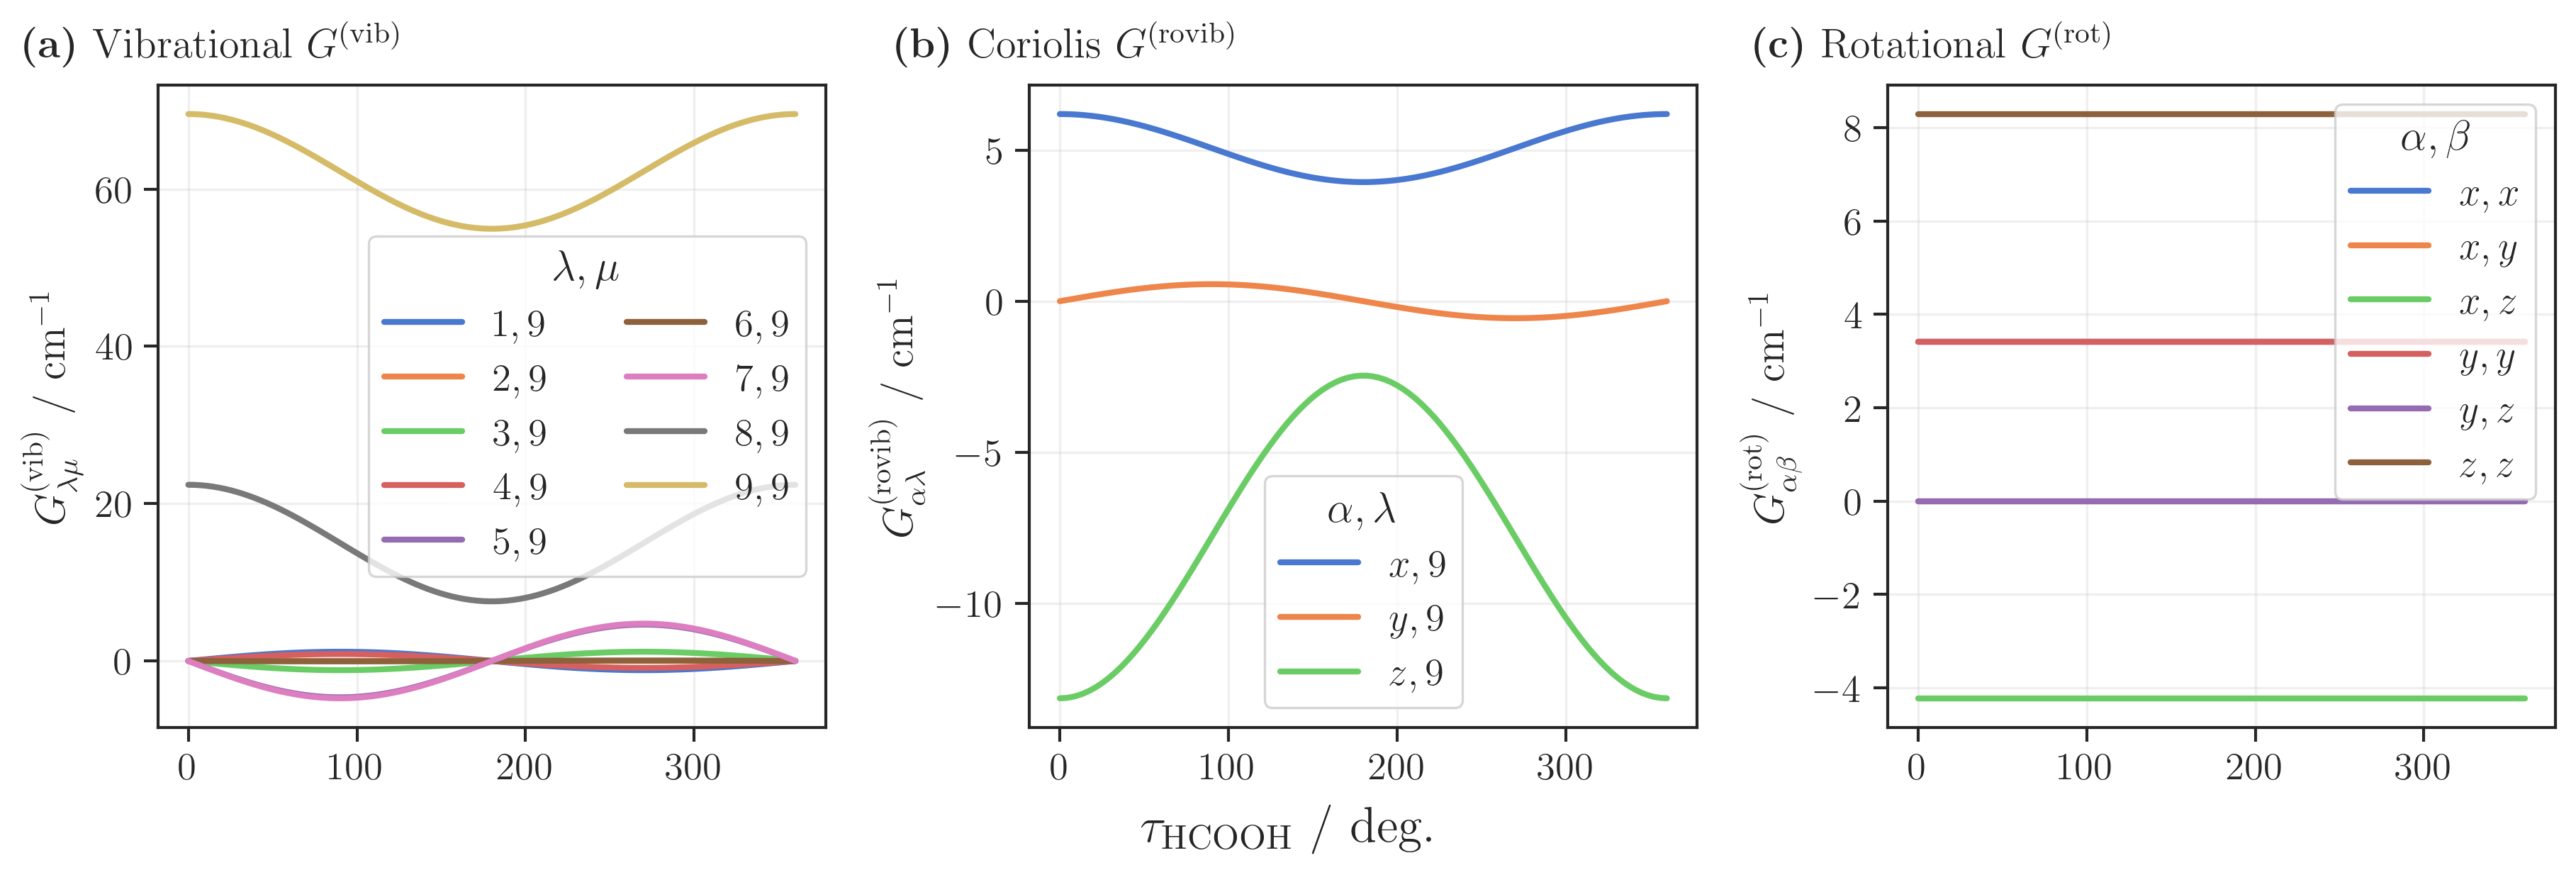

In [12]:
x = product_grid[:, -1] * 180.0 / np.pi

colors = sns.color_palette("muted", n_colors=ncoo)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 4),
    sharex=True,
    sharey=False,
    constrained_layout=True,
    gridspec_kw={"wspace": 0.05},
)

ax = axes[0]
j = ncoo - 1
for i, c in zip(range(ncoo), colors):
    ax.plot(
        x, gvib_sop_eval[:, i, j], label=rf"${{{i+1},{j+1}}}$", linewidth=2, color=c
    )

ax.set_ylabel(r"$G^{\mathrm{(vib)}}_{\lambda\mu}$ / $\mathrm{cm}^{-1}$")
ax.grid(True, alpha=0.3)
ax.legend(title=r"$\lambda,\mu$", ncol=2)

ax = axes[1]
alpha = ["x", "y", "z"]
j = ncoo - 1
for i, c in zip(range(3), colors):
    ax.plot(
        x,
        grovib_sop_eval[:, i, j],
        label=rf"${{{alpha[i]},{j+1}}}$",
        linewidth=2,
        color=c,
    )

ax.set_ylabel(r"$G^{\mathrm{(rovib)}}_{\alpha\lambda}$ / $\mathrm{cm}^{-1}$")
ax.grid(True, alpha=0.3)
ax.legend(title=r"$\alpha,\lambda$")

ax = axes[2]
alpha = ["x", "y", "z"]
ij = 0
for i in range(3):
    for j in range(i, 3):
        c = colors[ij]
        ax.plot(
            x,
            grot_sop_eval[:, i, j],
            label=rf"${{{alpha[i]},{alpha[j]}}}$",
            linewidth=2,
            color=c,
        )
        ij += 1

ax.set_ylabel(r"$G^{\mathrm{(rot)}}_{\alpha\beta}$ / $\mathrm{cm}^{-1}$")
ax.grid(True, alpha=0.3)
ax.legend(title=r"$\alpha,\beta$")

# panel labels
labels = [
    r"\textbf{(a)} Vibrational $G^{(\rm vib)}$",
    r"\textbf{(b)} Coriolis $G^{(\rm rovib)}$",
    r"\textbf{(c)} Rotational $G^{(\rm rot)}$",
]

for ax, lab in zip(axes.flat, labels):
    ax.text(
        -0.2,
        1.10,
        lab,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top",
    )

fig.supxlabel(r"$\tau_{\mathrm{HCOOH}}$ / deg.")

fig.savefig("hcooh_gmat_tau_plot.pdf", bbox_inches="tight", dpi=300)
plt.show()